# 01 — ReMedFiLM FULL architecture

Defines the proposed system exactly as implemented: four components, three inference outcomes, and the parameter arithmetic that closes.

**Evidence base**

- `reports/tables/phase26_component_inventory.csv`
- `reports/tables/phase24_module_spec.csv`
- `reports/audits/phase34_parameter_count_contract.json`
- `reports/audits/phase21_global_medfilm_architecture_binding.json`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 1.1 Component inventory — read from the frozen contract

In [3]:
parts = pd.read_csv(TABLES / "REMEDFILM_COMPONENT_PARAMETERS.csv")
parts[["symbol", "model_class", "role", "conditional", "parameters"]].to_string(index=False)

' symbol           model_class             role  conditional  parameters\n      G         GlobalMedFiLM GLOBAL_SEGMENTER        False     3523001\n  R_psi BARRRegionalRefinerV1 REGIONAL_REFINER         True     1276401\n  B_phi   BARRBenefitRouterV1   BENEFIT_ROUTER         True       36801\nS_omega      BARRPostSafetyV1      POST_SAFETY         True        1217\n   FULL             assembled  PROPOSED_SYSTEM         True     4837420'

In [4]:
comp = parts[parts.symbol != "FULL"].set_index("symbol").parameters.astype(int)
total = int(parts[parts.symbol == "FULL"].parameters.iloc[0])
print("FULL resident parameters:", total)
print("component sum           :", int(comp.sum()))
assert int(comp.sum()) == total
print()
for k, v in comp.items():
    print(f"  {k:8s} {v:>10,}  ({v / total:6.2%})")
print()
raw = pd.read_csv(REPO / "reports/tables/phase26_component_inventory.csv")
print("NOTE — phase26_component_inventory.csv has a units defect: it stores")
print(f"  G.parameters = {int(raw[raw.symbol == 'G'].parameters.iloc[0]):,} (that is MACs)")
print("The corrected derived table is used here. See DEFECT-01.")

FULL resident parameters: 4837420
component sum           : 4837420

  G         3,523,001  (72.83%)
  R_psi     1,276,401  (26.39%)
  B_phi        36,801  ( 0.76%)
  S_omega       1,217  ( 0.03%)

NOTE — phase26_component_inventory.csv has a units defect: it stores
  G.parameters = 31,551,740,928 (that is MACs)
The corrected derived table is used here. See DEFECT-01.


## 1.2 Backbone configuration — task conditioning and FiLM sites

In [5]:
b = json.loads((REPO / "reports/audits/phase21_global_medfilm_architecture_binding.json").read_text(encoding="utf-8"))
for k in ("architecture_id", "model_params", "film_sites", "film_equation",
          "task_embedding_dim", "channels", "heads"):
    if k in b:
        print(f"{k}: {b[k]}")

architecture_id: global_medfilm_shared_residual_unet_film5_no_se_no_deep_supervision_v1


## 1.3 The three inference outcomes

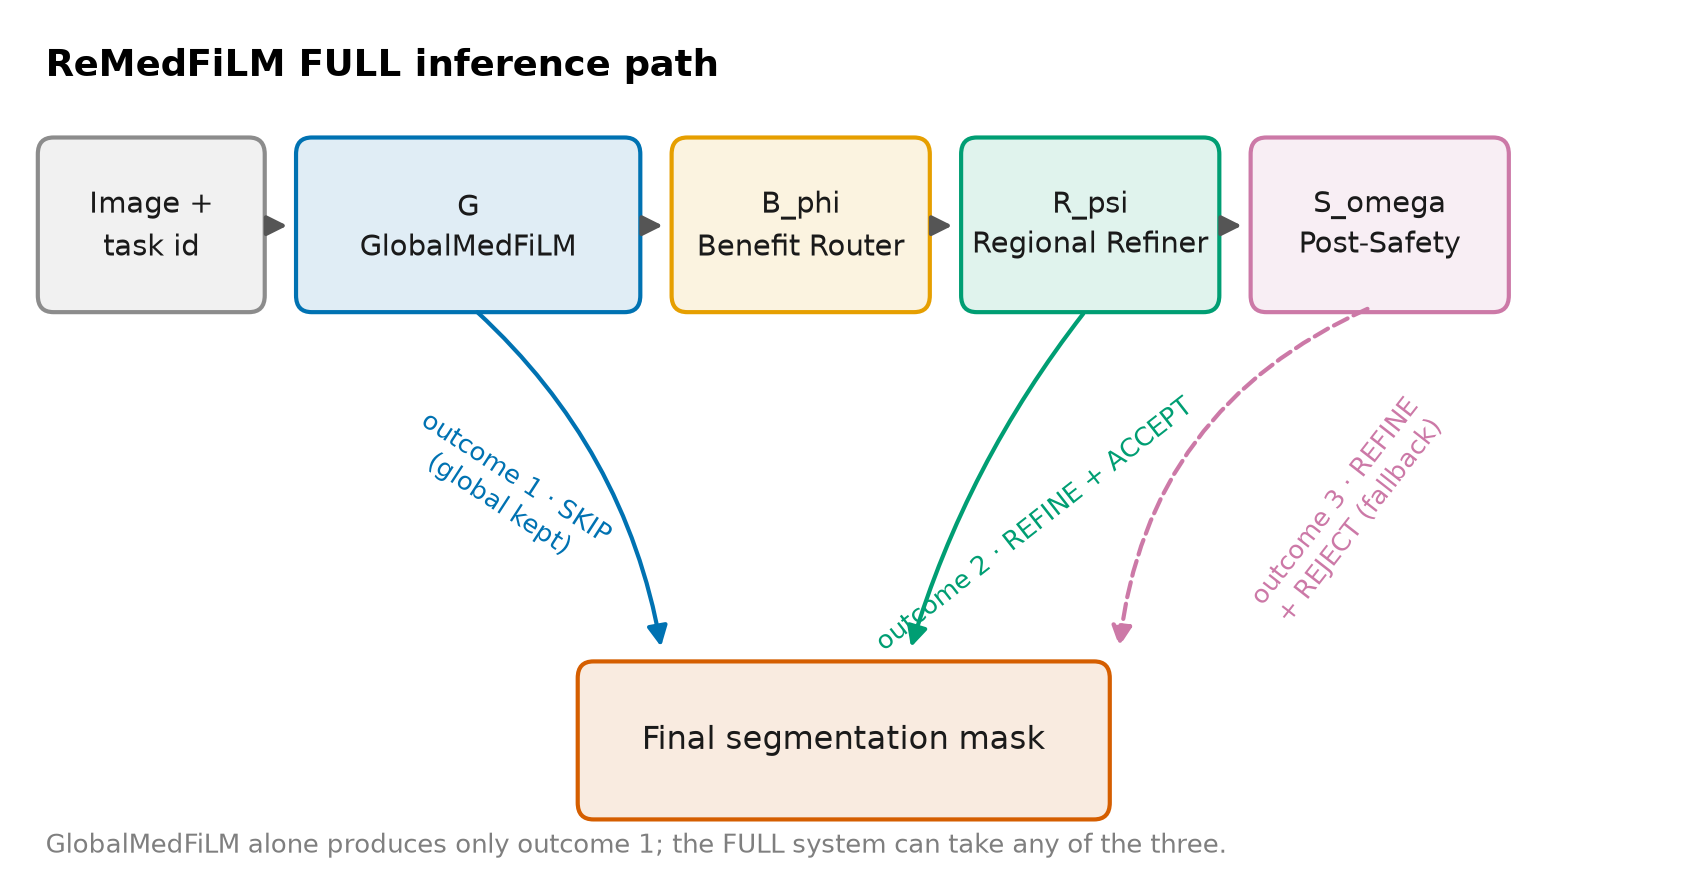

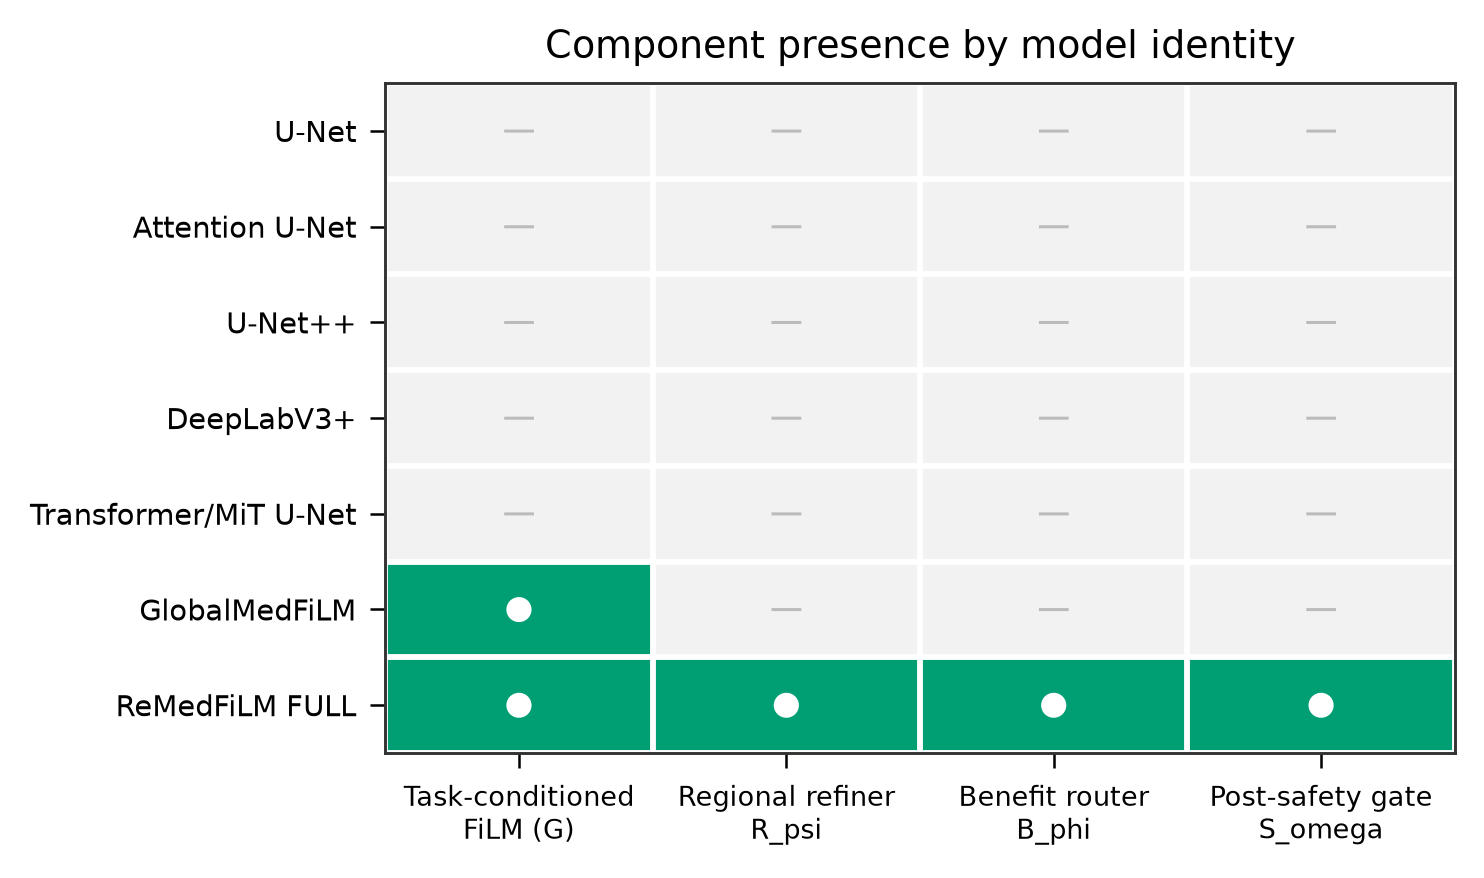

In [6]:
fig("Architecture", "A03_remedfilm_inference_path", width=780)
fig("Architecture", "A02_component_presence_matrix", width=520)

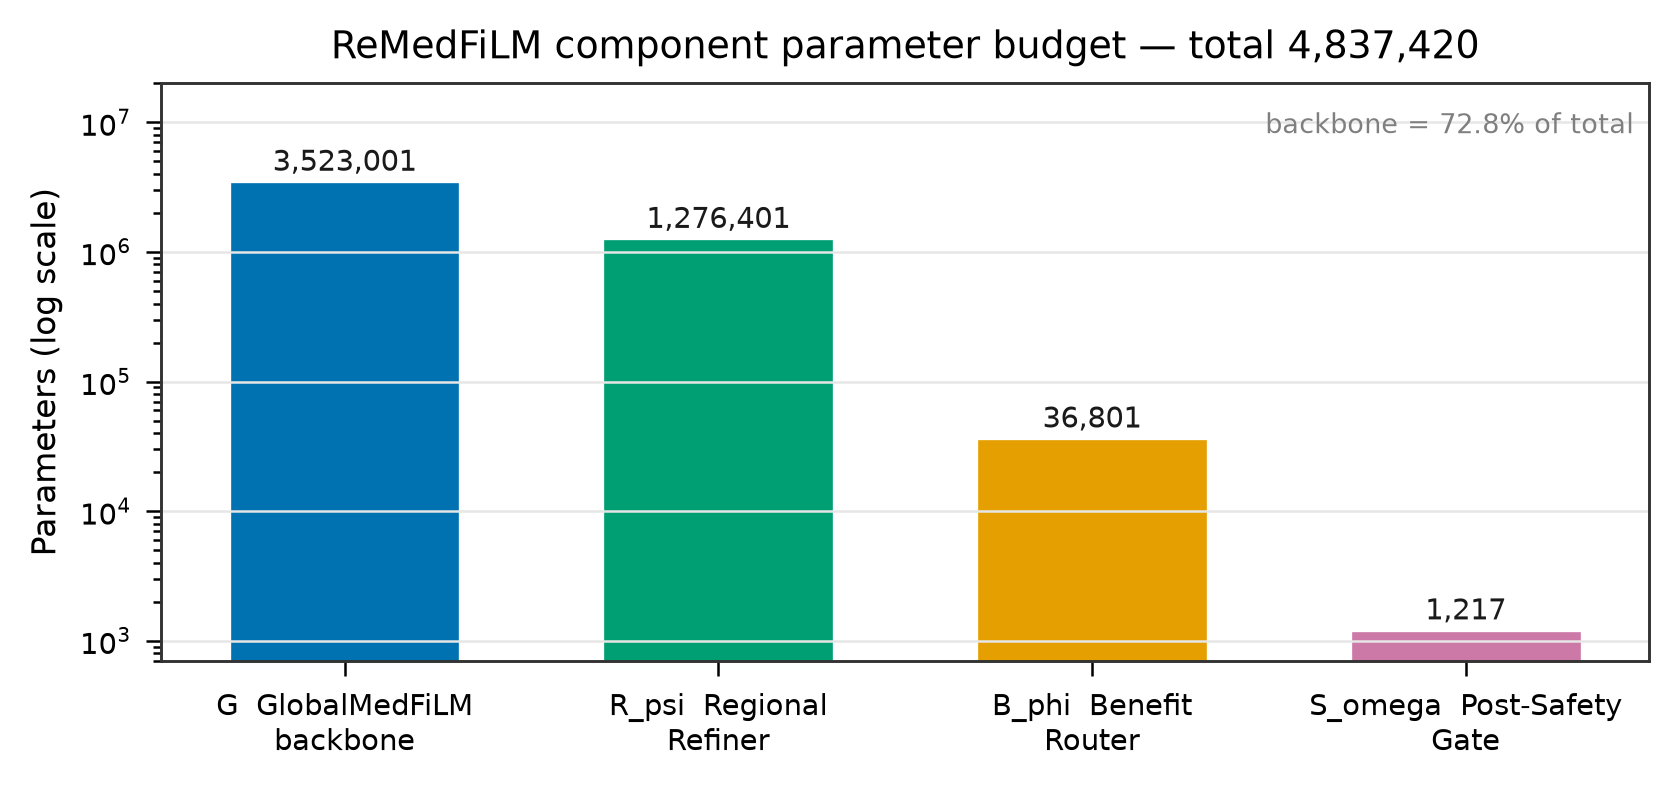

In [7]:
fig("Architecture", "A01_component_parameter_budget", width=720)

## 1.4 Assembly, not joint training

The four components were fitted **separately and sequentially**, each against a
frozen upstream:

| Stage | Fitted on | Upstream frozen |
|---|---|---|
| G — GlobalMedFiLM | TRAIN5832, VAL808 selection | — |
| R_psi — Regional Refiner | ROI crops from G's proposals, 3 cross-fitted folds | G |
| B_phi — Benefit Router | out-of-fold G+R gain labels | G, R |
| S_omega — Post-Safety Gate | routed candidates | G, R, B |

No optimiser ever saw all four modules at once. ReMedFiLM FULL is therefore an
**assembled inference system**, and every claim about it is a claim about that
assembly — not about joint end-to-end training.

In [8]:
print("Assembly contract")
print("-----------------")
print("1. G produces a global probability map and a proposal set.")
print("2. B_phi scores each proposal; the top budget fraction is selected.")
print("3. R_psi refines only the selected ROIs.")
print("4. S_omega accepts or vetoes each refined candidate.")
print("5. Accepted candidates replace the global mask locally; vetoed ones fall back.")
print()
print("Only the FULL assembly can produce outcomes 2 and 3. A GlobalMedFiLM")
print("checkpoint alone is never a ReMedFiLM FULL prediction.")

Assembly contract
-----------------
1. G produces a global probability map and a proposal set.
2. B_phi scores each proposal; the top budget fraction is selected.
3. R_psi refines only the selected ROIs.
4. S_omega accepts or vetoes each refined candidate.
5. Accepted candidates replace the global mask locally; vetoed ones fall back.

Only the FULL assembly can produce outcomes 2 and 3. A GlobalMedFiLM
checkpoint alone is never a ReMedFiLM FULL prediction.


In [9]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
